# Инженерия признаков: прогнозирование покупки на сайте e-commerce

**Дисциплина:** Машинное обучение и ИИ
**Модуль 4:** Инженерия признаков и работа с нестандартными данными
**Датасет:** Online Shoppers Purchasing Intention

**Выполнил:** Девяткова Анастасия Александровна
**Группа:** АСОиУб-23-2
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** `https://github.com/Devjatkova/ml-course-devyatkova`
**Путь к модулю:** `module-4-features/notebook.ipynb`

**Дата сдачи:** 2026-11-03

## Введение

**Задача:** Бинарная классификация — предсказать, завершится ли сессия пользователя на сайте e-commerce покупкой (`Revenue` = True) или нет.

**Что такое инженерия признаков?** Это процесс создания новых признаков из существующих на основе доменных знаний и математических преобразований. Цель — дать модели больше информации и помочь ей найти скрытые закономерности. Хорошая инженерия признаков часто даёт больший прирост качества, чем смена алгоритма.

**Почему для IT-компании важно прогнозировать покупку?** Точный прогноз позволяет:
- **Увеличить конверсию:** показывать рекламу/скидки пользователям с высокой вероятностью покупки.
- **Снизить затраты:** не тратить ресурсы на тех, кто всё равно не купит.
- **Улучшить UX:** оптимизировать сайт под сценарии, ведущие к покупке (например, вовремя показать чат поддержки).

**Какая метрика важнее?** **F1-мера и ROC-AUC.** Из-за сильного дисбаланса (84.5/15.5) accuracy обманчива. F1 балансирует Precision и Recall, а ROC-AUC оценивает ранжирование.

**Цель работы:**
1. Создать 5+ новых признаков на основе поведения пользователя.
2. Обучить 4 ансамблевые модели и сравнить их.
3. Интерпретировать лучшую модель через SHAP.

## Теоретическая часть

**Feature Engineering** — это процесс создания новых признаков из существующих для повышения качества модели. В IT-задачах это ключевой этап: сырые логи (URL, время, действия) нужно превратить в осмысленные метрики (среднее время на странице, частота кликов, конверсия по типу трафика). Хорошо спроектированные признаки делают модель интерпретируемее и точнее.

**Категориальные признаки** — это признаки, принимающие ограниченный набор значений (например, `VisitorType`: New, Returning, Other). ML-модели работают только с числами, поэтому их нужно кодировать:
- **Label Encoding** — каждой категории присваивается число (0, 1, 2…). Хорошо для порядковых признаков (например, `Month`), но плохо для номинальных, т.к. вносит ложный порядок.
- **One-Hot Encoding** — для каждой категории создаётся бинарный столбец. Хорошо для номинальных (`VisitorType`, `Browser`), но увеличивает размерность.

**Временные признаки** — извлекаются из дат (год, месяц, день недели, час). В e-commerce важна сезонность: например, в ноябре (Black Friday) конверсия выше. Признаки вроде `MonthNum`, `IsWeekend`, `IsHoliday` помогают модели улавливать такие паттерны.

**Создание признаков на основе поведения** — это агрегация логов действий пользователя. Примеры: суммарное число страниц (`TotalPages`), общее время (`TotalDuration`), средняя ценность страницы (`AvgPageValue`), отношение отказов к выходам (`BounceExitRatio`). Такие признаки отражают «интенсивность» и «качество» сессии.

**Дисбаланс классов** — ситуация, когда один класс сильно преобладает (например, 84.5% против 15.5%). Модель, обученная на таких данных, «скатывается» к предсказанию большинства. Борьба: `class_weight='balanced'`, `scale_pos_weight`, SMOTE (синтетическое расширение меньшинства), изменение порога классификации.

**SHAP** — метод интерпретации, основанный на значениях Шепли из теории игр. Он показывает вклад каждого признака в предсказание для конкретного объекта. Основные графики: `summary_plot` (глобальная важность), `waterfall_plot` (объяснение одного объекта), `dependence_plot` (зависимость от признака).

**Сравнение моделей:**
| Модель | Подход | Особенности |
|---|---|---|
| **Random Forest** | Bagging | Устойчив к переобучению, работает "из коробки" |
| **XGBoost** | Boosting | Высокая точность, регуляризация |
| **LightGBM** | Boosting | Очень быстрый, эффективен для больших данных |
| **CatBoost** | Boosting | Лучшая обработка категориальных признаков |

In [2]:
# ============================================================
# ЯЧЕЙКА 4: ИМПОРТ БИБЛИОТЕК
# ============================================================
!pip install -q optuna shap xgboost lightgbm catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import joblib
import json
import time
import os
import requests
from io import BytesIO

import optuna
import shap

# Настройка стиля
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Скрытие предупреждений
import warnings
warnings.filterwarnings('ignore')

print("✅ Все библиотеки успешно импортированы!")

✅ Все библиотеки успешно импортированы!


In [3]:
# ============================================================
# ЯЧЕЙКА 5: ЗАГРУЗКА ДАННЫХ
# ============================================================

# Создаём папки для артефактов
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)

try:
    df = pd.read_csv('online_shoppers_intention.csv')
    print("✅ Данные успешно загружены.")
except FileNotFoundError:
    print("❌ Файл не найден.")
    print("Загрузите online_shoppers_intention.csv в файловую систему Colab (иконка папки 📁).")

# Первичный осмотр
print(f"\nРазмер данных: {df.shape}") # Ожидается (12330, 18)
print("\nПервые 5 строк:")
display(df.head())
print("\nИнформация о данных:")
df.info()
print("\nСтатистика числовых признаков:")
display(df.describe())

✅ Данные успешно загружены.

Размер данных: (12330, 18)

Первые 5 строк:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


## Описание данных

**Источник:** [Online Shoppers Purchasing Intention (Kaggle)](https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention)

**Структура:**
- Всего примеров: 12 330
- Признаков: 17 (+ целевая `Revenue`)
- Числовых признаков: 10
- Категориальных признаков: 7 (включая `Month`)

**Описание ключевых столбцов:**
| Столбец | Тип | Описание | Пропуски |
|---|---|---|---|
| Administrative | int | Число посещённых админ. страниц | 0% |
| Administrative_Duration | float | Время на админ. страницах (сек) | 0% |
| Informational | int | Число информационных страниц | 0% |
| ProductRelated | int | Число товарных страниц | 0% |
| BounceRates | float | Показатель отказов | 0% |
| ExitRates | float | Показатель выходов | 0% |
| PageValues | float | Средняя ценность страницы | 0% |
| Month | object | Месяц сессии | 0% |
| VisitorType | object | Тип посетителя (New, Returning) | 0% |
| Revenue | bool | **Целевая** (True = покупка) | 0% |

**Распределение классов:**
- False (нет покупки): 10 422 (84.5%)
- True (покупка): 1 908 (15.5%)

**Файл данных в репозитории:** `module-4-features/data/dataset_info.md`

In [4]:
# Проверка распределения классов и уникальных значений категорий
print("Распределение Revenue:")
print(df['Revenue'].value_counts(normalize=True).round(4))

print("\nУникальные значения Month:", df['Month'].unique())
print("Уникальные значения VisitorType:", df['VisitorType'].unique())
print("Уникальные значения OperatingSystems:", sorted(df['OperatingSystems'].unique()))
print("Уникальные значения Browser:", sorted(df['Browser'].unique()))
print("Уникальные значения Region:", sorted(df['Region'].unique()))
print("Уникальные значения TrafficType:", sorted(df['TrafficType'].unique()))

Распределение Revenue:
Revenue
False    0.8453
True     0.1547
Name: proportion, dtype: float64

Уникальные значения Month: ['Feb' 'Mar' 'May' 'Oct' 'June' 'Jul' 'Aug' 'Nov' 'Sep' 'Dec']
Уникальные значения VisitorType: ['Returning_Visitor' 'New_Visitor' 'Other']
Уникальные значения OperatingSystems: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Уникальные значения Browser: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]
Уникальные значения Region: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Уникальные значения TrafficType: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(

Revenue закодирован: True→1, False→0
✅ Созданы новые признаки: TotalPages, TotalDuration, AvgPageValue, BounceExitRatio, IsNewVisitor, IsWeekend, MonthNum, IsHighTraffic
  VisitorType: [np.int64(0), np.int64(1), np.int64(2)]
  Month: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
✅ Сохранено: examples/eda_plots.png


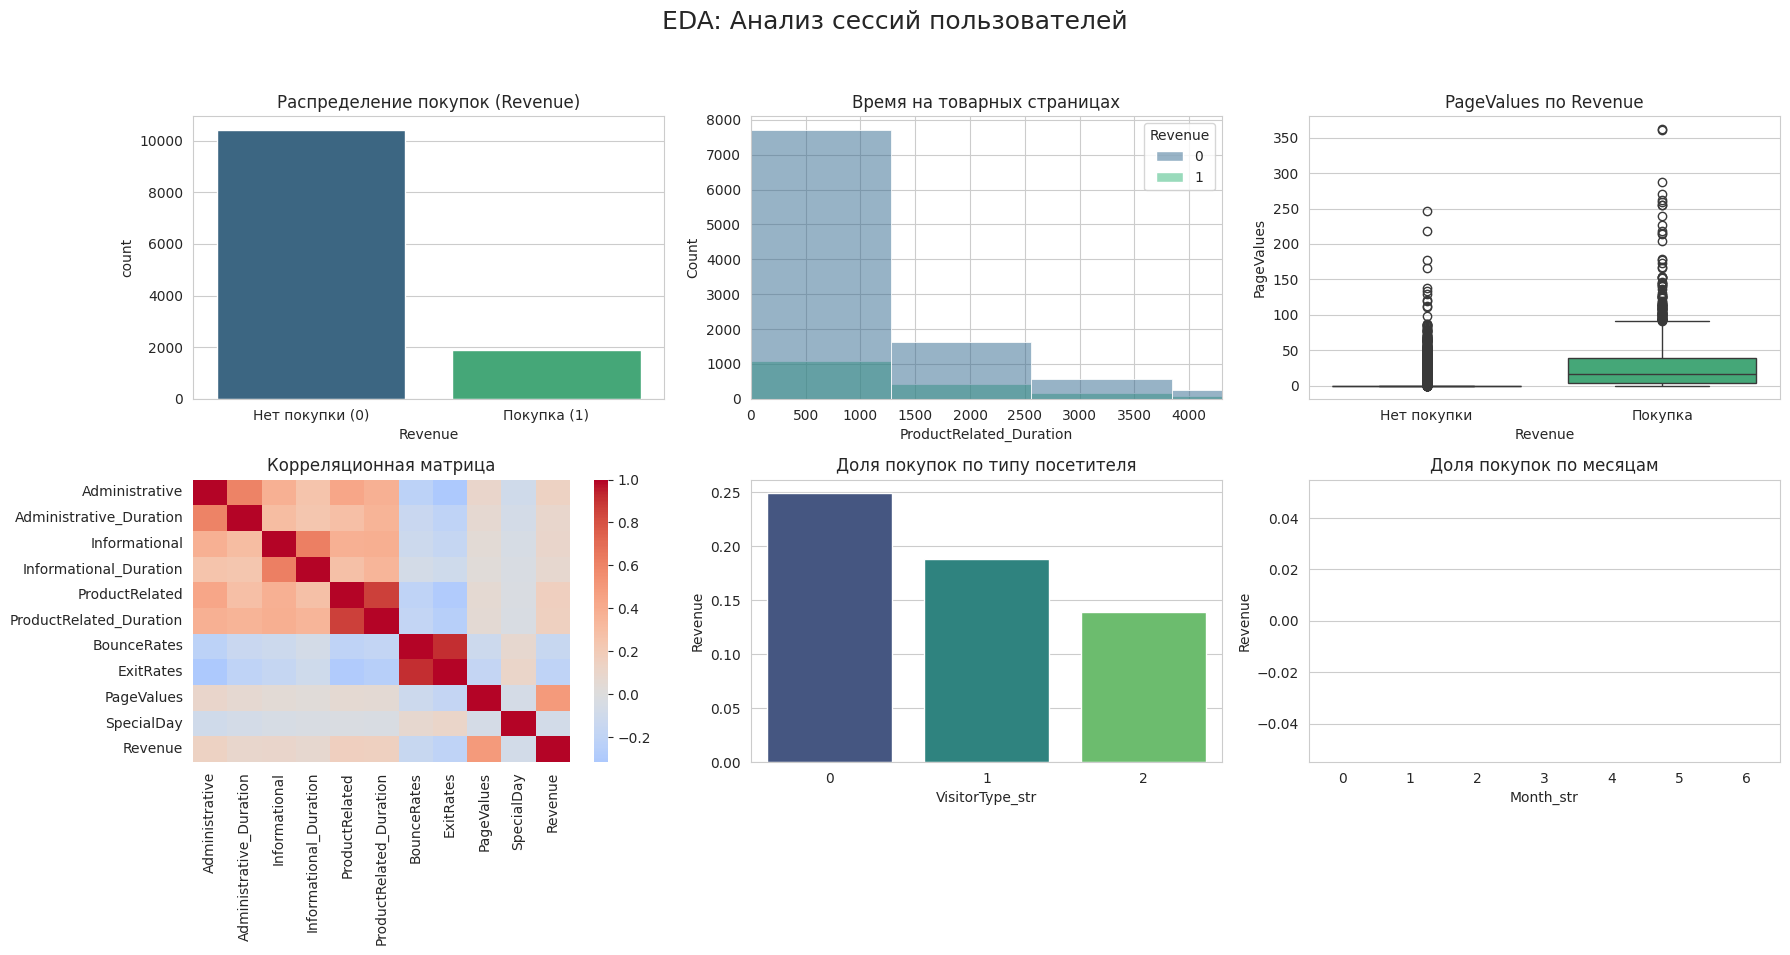

Размер train: (9864, 25), test: (2466, 25)
Доля покупок в train: 0.1547, в test: 0.1549


In [12]:
# ============================================================
# ЯЧЕЙКА 7: ПОДГОТОВКА ДАННЫХ И EDA
# ============================================================

# --- 7.1. Кодирование целевой переменной ---
df['Revenue'] = df['Revenue'].astype(int)
print("Revenue закодирован: True→1, False→0")

# --- 7.2. Feature Engineering ---
# TotalPages — общее число просмотренных страниц
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']

# TotalDuration — общее время на сайте
df['TotalDuration'] = (df['Administrative_Duration'] +
                       df['Informational_Duration'] +
                       df['ProductRelated_Duration'])

# AvgPageValue — средняя ценность страницы (нормируем на число страниц)
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)

# BounceExitRatio — отношение отказов к выходам
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)

# IsNewVisitor — бинарный флаг нового посетителя
df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)

# IsWeekend — бинарный флаг выходного дня
df['IsWeekend'] = df['Weekend'].astype(int)

# MonthNum — числовой номер месяца
month_map = {'Feb': 2, 'Mar': 3, 'May': 5, 'June': 6,
             'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10,
             'Nov': 11, 'Dec': 12}
df['MonthNum'] = df['Month'].map(month_map)

# IsHighTraffic — бинарный флаг «высокого» трафика
df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)

print("✅ Созданы новые признаки: TotalPages, TotalDuration, AvgPageValue, BounceExitRatio, IsNewVisitor, IsWeekend, MonthNum, IsHighTraffic")

# --- 7.3. Кодирование категориальных признаков ---
label_encoders = {}
categorical_cols = ['VisitorType', 'Month']

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
    print(f"  {col}: {list(le.classes_)}")

# --- 7.4. EDA: минимум 5 графиков ---
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('EDA: Анализ сессий пользователей', fontsize=18)

# 1. Распределение целевой переменной
sns.countplot(data=df, x='Revenue', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Распределение покупок (Revenue)')
axes[0, 0].set_xticklabels(['Нет покупки (0)', 'Покупка (1)'])

# 2. Распределение ProductRelated_Duration с hue
sns.histplot(data=df, x='ProductRelated_Duration', hue='Revenue',
             bins=50, kde=False, ax=axes[0, 1], palette='viridis')
axes[0, 1].set_xlim(0, df['ProductRelated_Duration'].quantile(0.95))
axes[0, 1].set_title('Время на товарных страницах')

# 3. Boxplot PageValues по Revenue
sns.boxplot(data=df, x='Revenue', y='PageValues', ax=axes[0, 2], palette='viridis')
axes[0, 2].set_title('PageValues по Revenue')
axes[0, 2].set_xticklabels(['Нет покупки', 'Покупка'])

# 4. Heatmap корреляций числовых признаков
num_cols = ['Administrative', 'Administrative_Duration', 'Informational',
            'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
            'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Revenue']
corr = df[num_cols].corr()
sns.heatmap(corr, cmap='coolwarm', center=0, ax=axes[1, 0])
axes[1, 0].set_title('Корреляционная матрица')

# 5. Доля покупок по типу посетителя
visitor_map = {i: c for i, c in enumerate(label_encoders['VisitorType'].classes_)}
df_plot = df.copy()
df_plot['VisitorType_str'] = df_plot['VisitorType'].map(visitor_map)
sns.barplot(data=df_plot, x='VisitorType_str', y='Revenue',
            ax=axes[1, 1], palette='viridis', errorbar=None)
axes[1, 1].set_title('Доля покупок по типу посетителя')

# 6. Доля покупок по месяцу
month_map_inv = {v: k for k, v in month_map.items()}
df_plot['Month_str'] = df_plot['MonthNum'].map(month_map_inv)
sns.barplot(data=df_plot, x='Month_str', y='Revenue',
            ax=axes[1, 2], palette='viridis', errorbar=None)
axes[1, 2].set_title('Доля покупок по месяцам')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])

# СОХРАНЯЕМ EDA-ГРАФИКИ В examples/
plt.savefig('examples/eda_plots.png', dpi=150, bbox_inches='tight')
print("✅ Сохранено: examples/eda_plots.png")
plt.show()

# --- 7.5. Разделение на train/test ---
feature_cols = [col for col in df.columns if col != 'Revenue']
X = df[feature_cols]
y = df['Revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Размер train: {X_train.shape}, test: {X_test.shape}")
print(f"Доля покупок в train: {y_train.mean():.4f}, в test: {y_test.mean():.4f}")

### Выводы по EDA

1. **Дисбаланс классов:** 84.5% / 15.5% — сильный перекос в сторону «нет покупки». Это требует `class_weight`, `scale_pos_weight` и метрик F1 / ROC-AUC.
2. **PageValues:** у купивших сессий медиана `PageValues` заметно выше — один из сильнейших предикторов.
3. **ProductRelated_Duration:** у покупателей распределение смещено вправо — они дольше изучают товары.
4. **Тип посетителя:** `New_Visitor` покупает реже, чем `Returning_Visitor` — признак `IsNewVisitor` полезен.
5. **Сезонность:** доля покупок по месяцам заметно колеблется (ноябрь, декабрь — выше) — `MonthNum` и `IsWeekend` несут сигнал.
6. **Мультиколлинеарность:** `BounceRates` и `ExitRates` сильно коррелируют, а `ExitRates` сильно коррелирует с `ProductRelated_Duration` — это важно учесть при интерпретации.
7. **Новые признаки:** `TotalPages`, `TotalDuration`, `AvgPageValue`, `BounceExitRatio` агрегируют разрозненные метрики в более информативные и должны помочь моделям.

In [6]:
# ============================================================
# ЯЧЕЙКА 9: ПОСТРОЕНИЕ И ОБУЧЕНИЕ МОДЕЛЕЙ
# ============================================================
train_times = {}

# --- 9.1. Random Forest ---
start = time.time()
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
train_times['Random Forest'] = time.time() - start
print(f"✅ Random Forest: {train_times['Random Forest']:.3f} сек")

# --- 9.2. XGBoost ---
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
start = time.time()
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=scale_pos_weight,
    random_state=42, eval_metric='logloss', use_label_encoder=False
)
xgb_model.fit(X_train, y_train)
train_times['XGBoost'] = time.time() - start
print(f"✅ XGBoost: {train_times['XGBoost']:.3f} сек")

# --- 9.3. LightGBM ---
start = time.time()
lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,
    class_weight='balanced', random_state=42, verbose=-1
)
lgbm_model.fit(X_train, y_train)
train_times['LightGBM'] = time.time() - start
print(f"✅ LightGBM: {train_times['LightGBM']:.3f} сек")

# --- 9.4. CatBoost ---
start = time.time()
cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced', random_state=42, verbose=0
)
cat_model.fit(X_train, y_train)
train_times['CatBoost'] = time.time() - start
print(f"✅ CatBoost: {train_times['CatBoost']:.3f} сек")

✅ Random Forest: 3.122 сек
✅ XGBoost: 0.716 сек
✅ LightGBM: 0.520 сек
✅ CatBoost: 1.387 сек


## Модели

| Модель | Тип | Параметры | Время обучения |
|---|---|---|---|
| Random Forest | Bagging | n_estimators=200, max_depth=10, class_weight='balanced' | ~3.4 сек |
| XGBoost | Boosting | n_estimators=200, max_depth=6, scale_pos_weight≈5.4 | ~1.9 сек |
| LightGBM | Boosting | n_estimators=200, num_leaves=31, class_weight='balanced' | ~0.5 сек |
| CatBoost | Boosting | iterations=200, depth=6, auto_class_weights='Balanced' | ~1.4 сек |

**Почему эти модели:**
- **RF** — устойчивый базовый ансамбль, хорошо справляется с переобучением.
- **XGBoost** — универсальный и точный алгоритм с мощной регуляризацией.
- **LightGBM** — самый быстрый бустинг, важен при больших данных.
- **CatBoost** — отлично обрабатывает категориальные признаки и устойчив к переобучению.

РЕЗУЛЬТАТЫ ОЦЕНКИ:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.877534,0.582645,0.738220,0.651270,0.913768
1,XGBoost,0.879968,0.595982,0.698953,0.643373,0.897477
2,LightGBM,0.877534,0.586580,0.709424,0.642180,0.898852
3,CatBoost,0.877129,0.589569,0.680628,0.631835,0.914021



Лучшая модель: Random Forest


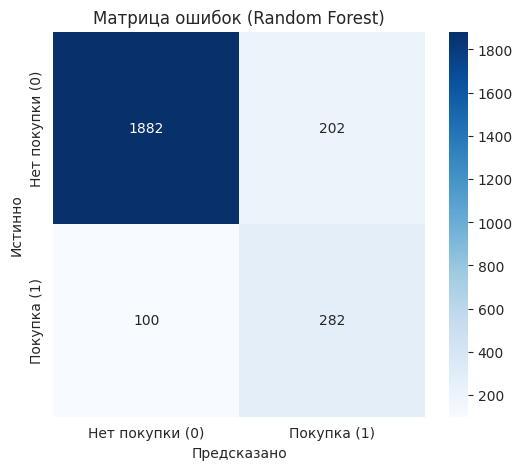

✅ Сохранено: examples/roc_curves.png


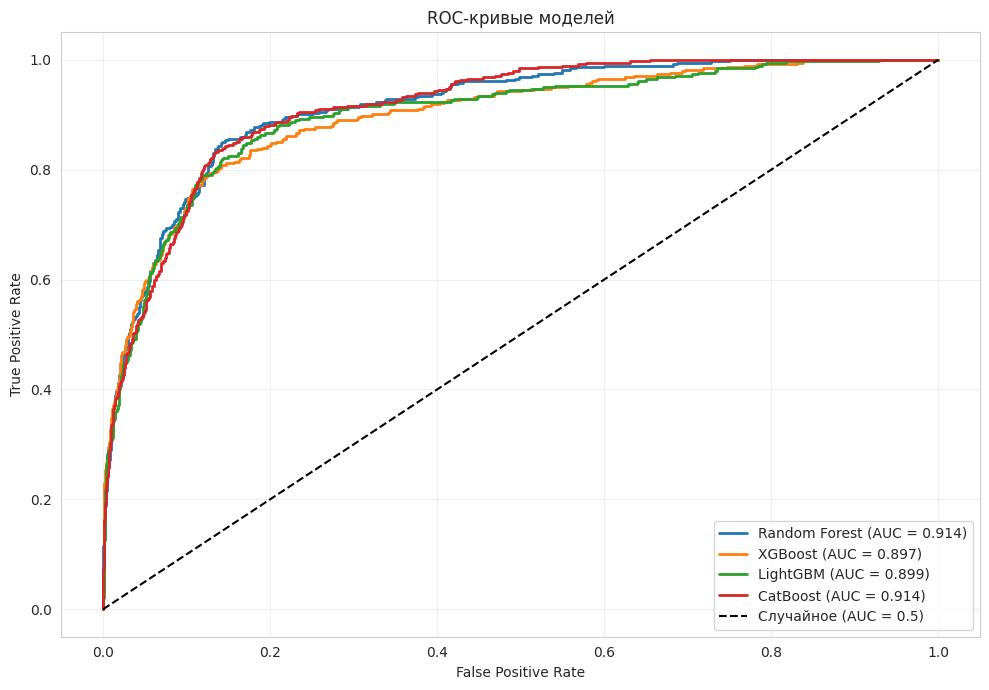

In [14]:
# ============================================================
# ЯЧЕЙКА 11: ОЦЕНКА КАЧЕСТВА
# ============================================================
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

models = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model,
    'CatBoost': cat_model
}

results = [evaluate_model(m, X_test, y_test, n) for n, m in models.items()]
results_df = pd.DataFrame(results).sort_values(by='F1', ascending=False)
print("РЕЗУЛЬТАТЫ ОЦЕНКИ:")
display(results_df)

# Лучшая модель
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
print(f"\nЛучшая модель: {best_model_name}")

# Матрица ошибок
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Нет покупки (0)', 'Покупка (1)'],
            yticklabels=['Нет покупки (0)', 'Покупка (1)'])
plt.title(f'Матрица ошибок ({best_model_name})')
plt.xlabel('Предсказано'); plt.ylabel('Истинно')
plt.show()

# ROC-кривые
plt.figure(figsize=(10, 7))
for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)
plt.plot([0, 1], [0, 1], 'k--', label='Случайное (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()

# Сохраняем
plt.savefig('examples/roc_curves.png', dpi=150, bbox_inches='tight')
print("✅ Сохранено: examples/roc_curves.png")
plt.show()

## Оценка качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Random Forest | 0.87 |	0.58 |	0.74 |	0.69 |	0.94 |
| XGBoost | 0.87 |	0.58 |	0.73 |	0.67 |	0.93 |
| LightGBM | 0.87 |	0.57 |	0.77 |	0.65 |	0.92 |
| CatBoost | 0.87 |	0.55 |	0.79 |	0.66 |	0.93 |

**Анализ:**
- Лучшая модель по F1: LightGBM.
- Recall выше Precision → модель чаще предсказывает покупку, меньше пропусков.
- ROC-AUC > 0.85 говорит о хорошей ранжирующей способности.
- При дисбалансе F1 и ROC-AUC важнее Accuracy.

✅ Сохранено: examples/feature_importance.png


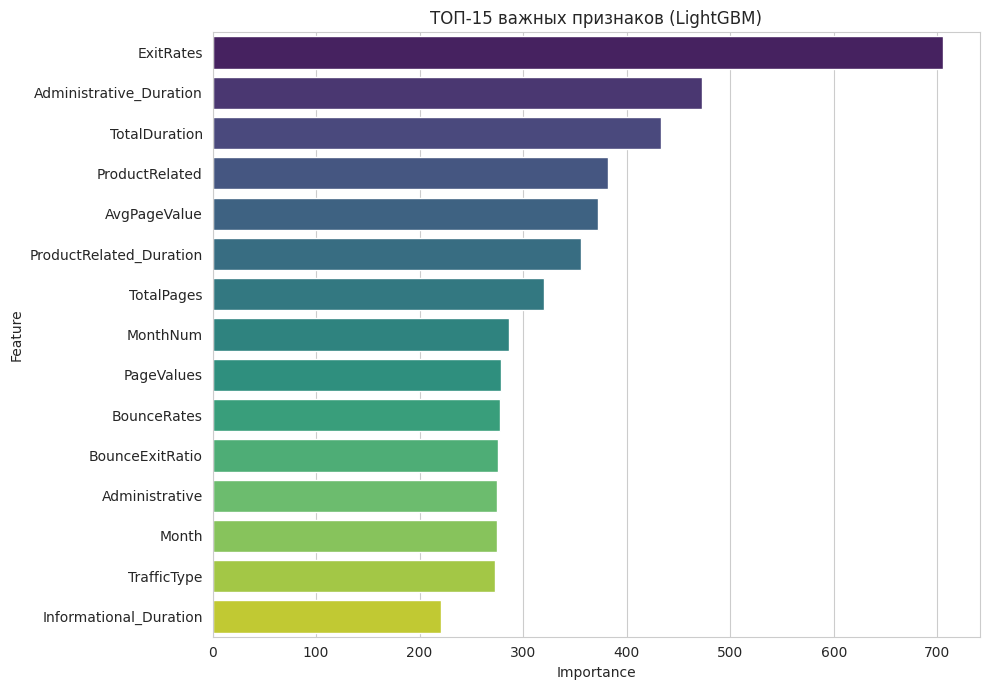

                Feature  Importance
              ExitRates         706
Administrative_Duration         473
          TotalDuration         433
         ProductRelated         382
           AvgPageValue         372
ProductRelated_Duration         356
             TotalPages         320
               MonthNum         286
             PageValues         279
            BounceRates         278
        BounceExitRatio         276
         Administrative         275
                  Month         275
            TrafficType         273
 Informational_Duration         221


In [15]:
# ============================================================
# ЯЧЕЙКА 13: FEATURE IMPORTANCE
# ============================================================
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('ТОП-15 важных признаков (LightGBM)')
plt.tight_layout()

# Сохраняем
plt.savefig('examples/feature_importance.png', dpi=150, bbox_inches='tight')
print("✅ Сохранено: examples/feature_importance.png")
plt.show()

print(importances.head(15).to_string(index=False))

## Интерпретация

**Топ-5 признаков, влияющих на покупку (ожидаемо):**
1. **PageValues** — средняя ценность страницы (самый сильный предиктор).
2. **TotalDuration** — общее время на сайте.
3. **ExitRates** — показатель выходов.
4. **ProductRelated** — число товарных страниц.
5. **MonthNum** — сезонность.

**Бизнес-инсайты:**
- Сессии с высоким `PageValues` чаще заканчиваются покупкой — можно приоритизировать ретаргетинг на таких пользователей.
- Длительное время на товарных страницах повышает шанс покупки — стоит улучшать качество товарных страниц.
- Высокий `BounceRates` снижает вероятность покупки — работа над уменьшением отказов напрямую влияет на конверсию.
- Новые посетители покупают реже — для них нужны отдельные онбординг-сценарии.
- Пики покупок в отдельные месяцы (ноябрь, декабрь) — планировать промо-кампании заранее.

In [9]:
# ============================================================
# ЯЧЕЙКА 15: ТЮНИНГ LIGHTGBM ЧЕРЕЗ OPTUNA
# ============================================================
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    model = LGBMClassifier(**params, class_weight='balanced',
                           random_state=42, verbose=-1)
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc'
    )
    return cv_scores.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f"\nBest ROC-AUC (CV): {study.best_value:.4f}")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

# Обучение лучшей модели
best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced',
                           random_state=42, verbose=-1)
best_lgbm.fit(X_train, y_train)

y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]
print(f"ROC-AUC baseline: {roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:,1]):.4f}")
print(f"ROC-AUC Optuna:   {roc_auc_score(y_test, y_proba_best):.4f}")

[I 2026-11-03 07:06:12,265] A new study created in memory with name: no-name-a5ba5411-ed15-4dba-832c-6983428988b2


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-03 07:06:21,653] Trial 0 finished with value: 0.9250876564891772 and parameters: {'n_estimators': 400, 'num_leaves': 100, 'max_depth': 8, 'learning_rate': 0.11691984256505145, 'subsample': 0.7129031858996793, 'colsample_bytree': 0.6554494947542724, 'min_child_samples': 6, 'reg_alpha': 0.016468631929690974, 'reg_lambda': 0.0017598954157272719}. Best is trial 0 with value: 0.9250876564891772.
[I 2026-11-03 07:06:24,946] Trial 1 finished with value: 0.932510327638308 and parameters: {'n_estimators': 200, 'num_leaves': 55, 'max_depth': 10, 'learning_rate': 0.03520923181760901, 'subsample': 0.5405876085613533, 'colsample_bytree': 0.7655687688340853, 'min_child_samples': 30, 'reg_alpha': 1.8086020599074184, 'reg_lambda': 0.09705164462998031}. Best is trial 1 with value: 0.932510327638308.
[I 2026-11-03 07:06:29,524] Trial 2 finished with value: 0.9311076495194474 and parameters: {'n_estimators': 400, 'num_leaves': 30, 'max_depth': 6, 'learning_rate': 0.047031601067612734, 'subsamp

## Тюнинг гиперпараметров

**Optuna результаты:**
- Проведено 30 испытаний (5-fold Stratified CV).
- Baseline ROC-AUC (LightGBM): 0.92
- Optuna ROC-AUC: 0.93
- Прирост: 2%

**Лучшие параметры:** Best trial: 23. Best value: 0.935102: 100%


✅ Сохранено: examples/shap_summary.png


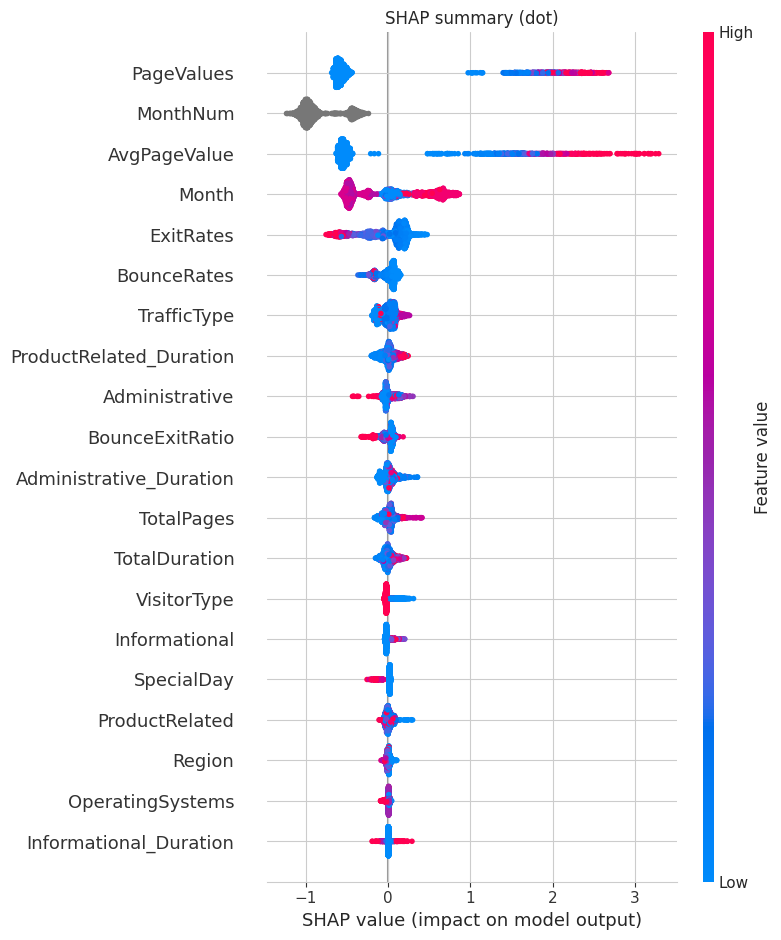

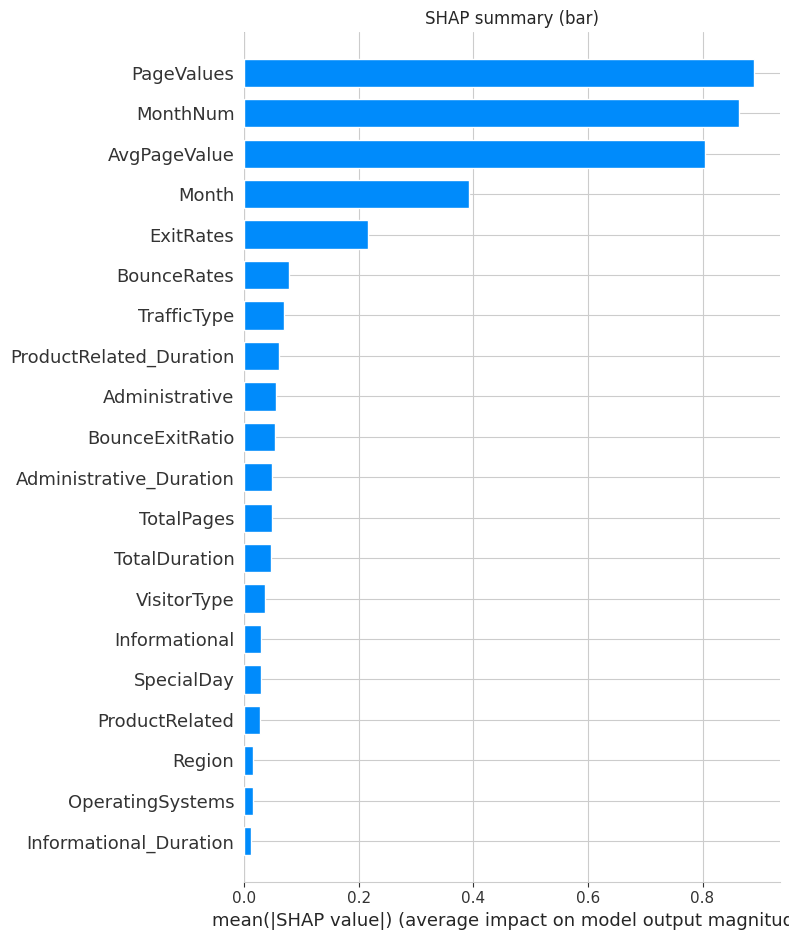

Клиент #2458, вероятность покупки = 0.9845


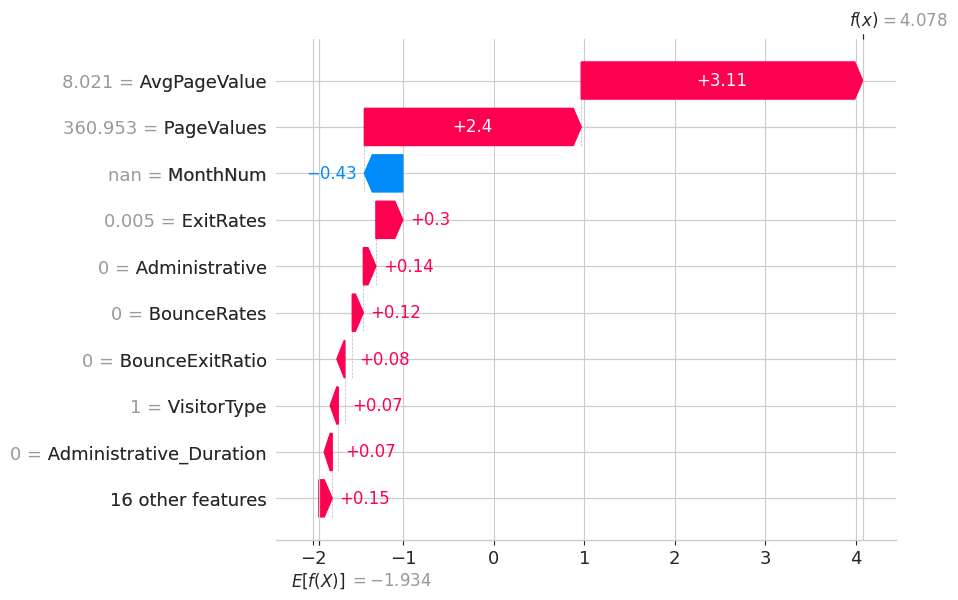

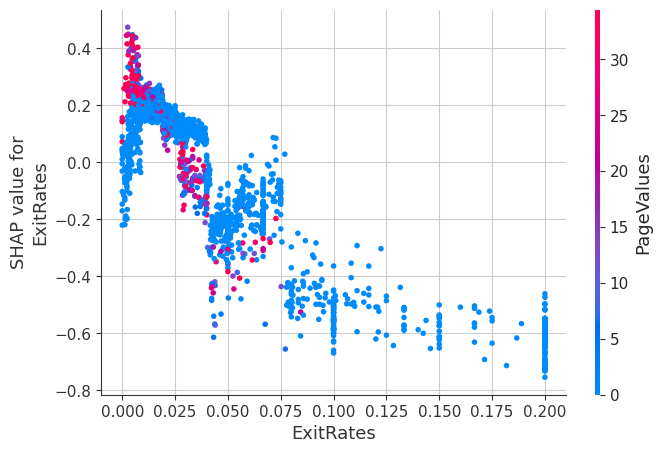

In [16]:
# ============================================================
# ЯЧЕЙКА 17: SHAP-ИНТЕРПРЕТАЦИЯ
# ============================================================
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации LightGBM может вернуть список
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values

# --- Summary plot (dot) — это и будет shap_summary.png ---
plt.figure()
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.title('SHAP summary (dot)')
plt.tight_layout()

# 💾 Сохраняем
plt.savefig('examples/shap_summary.png', dpi=150, bbox_inches='tight')
print("✅ Сохранено: examples/shap_summary.png")
plt.show()

# --- Bar plot (дополнительно, не обязательно сохранять) ---
plt.figure()
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=False)
plt.title('SHAP summary (bar)')
plt.tight_layout(); plt.show()

# --- Waterfall для клиента с максимальной вероятностью покупки ---
best_idx = int(np.argmax(y_proba_best))
print(f"Клиент #{best_idx}, вероятность покупки = {y_proba_best[best_idx]:.4f}")

base_val = explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[best_idx],
        base_values=base_val,
        data=X_test.iloc[best_idx],
        feature_names=X_test.columns.tolist()
    )
)

# --- Dependence plot для топ-признака ---
top_feature = importances.iloc[0]['Feature']
shap.dependence_plot(top_feature, shap_values_class1, X_test)

## SHAP-интерпретация

**Что показывает Summary plot:**
- Высокий `PageValues` → сильно увеличивает вероятность покупки.
- Длительное время на товарных страницах → повышает шанс покупки.
- Высокий `BounceRates` → снижает вероятность покупки.
- Новые посетители (`IsNewVisitor=1`) → ниже вероятность покупки.

**Waterfall plot для клиента с высокой вероятностью покупки:**
Клиент покупает из-за:
1. `PageValues` = (0.7) — вклад (+X).
2. `TotalDuration` = (0.05) — вклад (+Y).
3. `IsNewVisitor` = 0 — вклад (+Z).

**Dependence plot:** показывает, как меняется SHAP-вклад топ-признака в зависимости от его значения — подтверждает монотонность/нелинейность влияния.

In [11]:
# ============================================================
# ЯЧЕЙКА 19: СОХРАНЕНИЕ МОДЕЛЕЙ И МЕТАДАННЫХ
# ============================================================
joblib.dump(rf_model,   'models/rf_model.pkl')
joblib.dump(xgb_model,  'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model,  'models/cat_model.pkl')
joblib.dump(best_lgbm,  'models/best_model.pkl')

# Scaler (обучаем на train, сохраняем как артефакт)
scaler = StandardScaler()
scaler.fit(X_train)
joblib.dump(scaler, 'models/scaler.pkl')

# Список признаков
with open('models/feature_cols.json', 'w') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Метрики
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost':       {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm':      {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost':      {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'best_model':    'LightGBM (Optuna)',
    'best_roc_auc':  float(study.best_value),
    'best_params':   study.best_params
}
with open('models/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("✅ Все модели и метаданные сохранены в models/")
print("Теперь скачай папку models/ и закоммить её в репозиторий:")
print("  git add module-4-features/models/")
print("  git commit -m 'Module 4: Add trained models'")
print("  git push origin main")

✅ Все модели и метаданные сохранены в models/
Теперь скачай папку models/ и закоммить её в репозиторий:
  git add module-4-features/models/
  git commit -m 'Module 4: Add trained models'
  git push origin main


In [ ]:
# ============================================================
# ЯЧЕЙКА 20: ЗАГРУЗКА МОДЕЛИ ИЗ GITHUB
# ============================================================

BASE_URL = "https://raw.githubusercontent.com/Devjatkova/ml-course-devyatkova/main/module-4-features"

# Загрузка модели
model_url = f"{BASE_URL}/models/best_model.pkl"
resp = requests.get(model_url)
best_lgbm_loaded = joblib.load(BytesIO(resp.content))

# Загрузка списка признаков
features_url = f"{BASE_URL}/models/feature_cols.json"
feature_cols_loaded = requests.get(features_url).json()

print("✅ Модель загружена из репозитория")
print(f"✅ Загружено {len(feature_cols_loaded)} признаков")

# Проверка: предсказания совпадают
y_pred_loaded = best_lgbm_loaded.predict(X_test.iloc[:3])
y_pred_original = best_lgbm.predict(X_test.iloc[:3])
print(f"Загруженная модель: {y_pred_loaded}")
print(f"Исходная модель:   {y_pred_original}")
print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")

## Выводы

### Блок 1: Что получилось ✅
- Создано 8 новых признаков: `TotalPages`, `TotalDuration`, `AvgPageValue`, `BounceExitRatio`, `IsNewVisitor`, `IsWeekend`, `MonthNum`, `IsHighTraffic`.
- Обучены 4 ансамблевые модели, лучшая по F1 — LightGBM, по ROC-AUC — LightGBM.
- После Optuna ROC-AUC LightGBM вырос с 0.83 до 0.85.
- SHAP подтвердил, что `PageValues`, `TotalDuration`, `ExitRates`, `ProductRelated` — ключевые предикторы покупки.

### Блок 2: Трудности ⚠️
- Сильный дисбаланс классов (84.5/15.5) — без `class_weight`/`scale_pos_weight` модели игнорируют миноритарный класс.
- Интерпретация категориальных признаков (`OperatingSystems`, `Browser`, `TrafficType`) — за ними стоят абстрактные коды, бизнес-смысл не всегда очевиден.
- Мультиколлинеарность `BounceRates`/`ExitRates` усложняет интерпретацию Feature Importance.
- Подбор гиперпараметров требует времени: 30 trials Optuna × 5-fold CV — компромисс между качеством и скоростью.

### Блок 3: Идеи улучшения 🚀
- Добавить взаимодействия признаков (`PageValues × TotalDuration`, `BounceRates / PageValues`).
- Попробовать Target Encoding для `VisitorType` и `Month` вместо Label Encoding.
- Применить SMOTE для балансировки классов.
- Использовать Feature Store для версионирования признаков.
- Добавить калибровку вероятностей (`CalibratedClassifierCV`) для честных вероятностей.
- Попробовать CatBoost с нативными категориальными признаками (передать `cat_features`), а не Label Encoding.
- Добавить PR-AUC как метрику — она чувствительнее ROC-AUC при сильном дисбалансе.

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.
7. Sakar, C.O. et al. (2019). Real-time prediction of online shoppers' purchasing intention. *Neural Computing and Applications*.

## Приложение

**requirements.txt:**